Group Members
Wajeeha Ali (CS-22055)
Tooba Fatima (CS-22056)
Asiya Fatima Tabassum (CS-22064)

In [4]:
import joblib
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import zscore
import matplotlib.pyplot as plt
from sklearn.utils import resample
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, ConfusionMatrixDisplay
)
import tensorflow as tf
from tensorflow.keras import models
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import regularizers 

In [ ]:
# Load data
df = pd.read_csv('weatherHistory.csv')

Original Summary value counts:
Summary
Partly Cloudy                          31733
Mostly Cloudy                          28094
Overcast                               16597
Clear                                  10890
Foggy                                   7148
Breezy and Overcast                      528
Breezy and Mostly Cloudy                 516
Breezy and Partly Cloudy                 386
Dry and Partly Cloudy                     86
Windy and Partly Cloudy                   67
Light Rain                                63
Breezy                                    54
Windy and Overcast                        45
Humid and Mostly Cloudy                   40
Drizzle                                   39
Breezy and Foggy                          35
Windy and Mostly Cloudy                   35
Dry                                       34
Humid and Partly Cloudy                   17
Dry and Mostly Cloudy                     14
Rain                                      10
Windy           

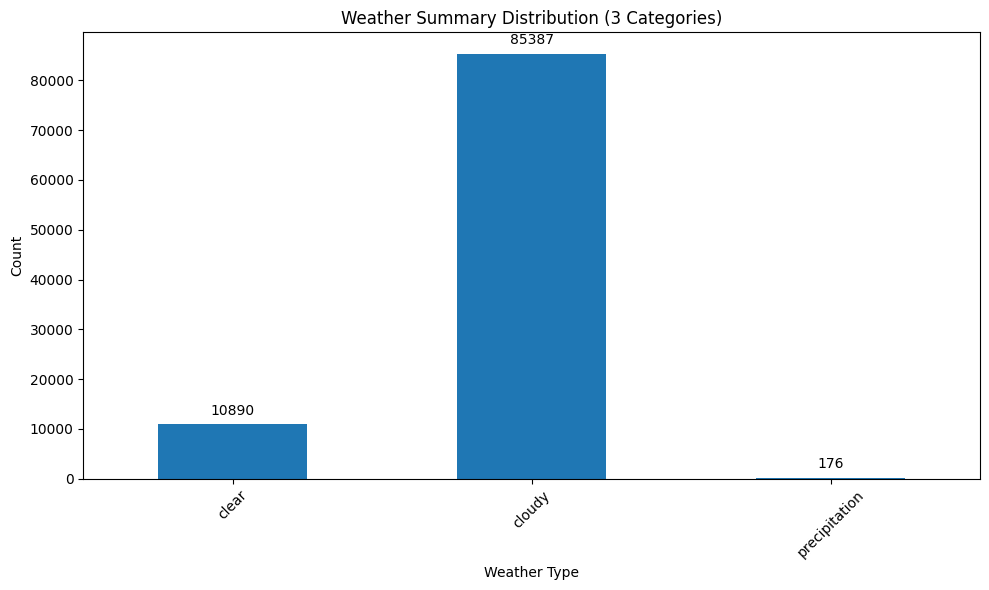


Complete DataFrame Columns:
['Formatted Date', 'Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Simple_Summary', 'Simple_Summary_Class']


In [6]:
# 1. First check original summary distribution
print("Original Summary value counts:")
print(df['Summary'].value_counts())

def simplify_summary(original):
    """Map original weather summary to 3 simplified classes"""
    original = str(original).lower()
    
    # 1. Precipitation (all wet conditions)
    if any(word in original for word in ['rain', 'drizzle', 'humid']):
        return 'precipitation'
    
    # 2. Clear (only completely clear skies)
    elif 'clear' in original:
        return 'clear'
    
    # 3. Cloudy (everything else - partial/mostly/overcast clouds)
    else:
        return 'cloudy'

# Apply the mapping
df['Simple_Summary'] = df['Summary'].apply(simplify_summary)

# ====== ADDED LABEL ENCODING HERE ======
# Define the mapping from text to numbers
summary_mapping = {
    'clear': 0,
    'cloudy': 1,
    'precipitation': 2
}

# Create new numerical column
df['Simple_Summary_Class'] = df['Simple_Summary'].map(summary_mapping)
# =======================================

# Verify the distribution (both original and encoded)
print("\nSimplified Weather Classes (Text):")
print(df['Simple_Summary'].value_counts())

print("\nSimplified Weather Classes (Encoded):")
print(df['Simple_Summary_Class'].value_counts())

# Visualize with all categories guaranteed (using text labels)
plt.figure(figsize=(10,6))
ax = df['Simple_Summary'].value_counts().reindex(['clear', 'cloudy', 'precipitation']).plot(kind='bar')

# Add value labels on bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
               (p.get_x() + p.get_width()/2., p.get_height()),
               ha='center', va='center',
               xytext=(0, 10),
               textcoords='offset points')

plt.title('Weather Summary Distribution (3 Categories)')
plt.xlabel('Weather Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df.drop(['Summary', 'Loud Cover', 'Daily Summary', 'Precip Type', 'Aparent Temperature (C)'], axis=1, inplace=True, errors='ignore')
print("\nComplete DataFrame Columns:")
print(df.columns.tolist())

In [7]:
# Drop unnecessary columns
df.drop(['Summary', 'Formatted Date', 'Loud Cover', 'Daily Summary', 'Apparent Temperature (C)', 'Precip Type'], axis=1, inplace=True, errors='ignore')
print("Current columns in DataFrame:", df.columns.tolist())

Current columns in DataFrame: ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Simple_Summary', 'Simple_Summary_Class']


REMOVING THE DUPLICATES

In [8]:
# Check for duplicates (optional: print duplicates before removal)
duplicates = df[df.duplicated(keep=False)]
print(f"Number of fully duplicate rows before removal: {len(duplicates)}")

# Remove duplicates (keeping the first occurrence)
df_cleaned = df.drop_duplicates(keep='first')

# Verify removal
remaining_duplicates = df_cleaned[df_cleaned.duplicated(keep=False)]
print(f"Number of duplicates after removal: {len(remaining_duplicates)}")

Number of fully duplicate rows before removal: 146
Number of duplicates after removal: 0


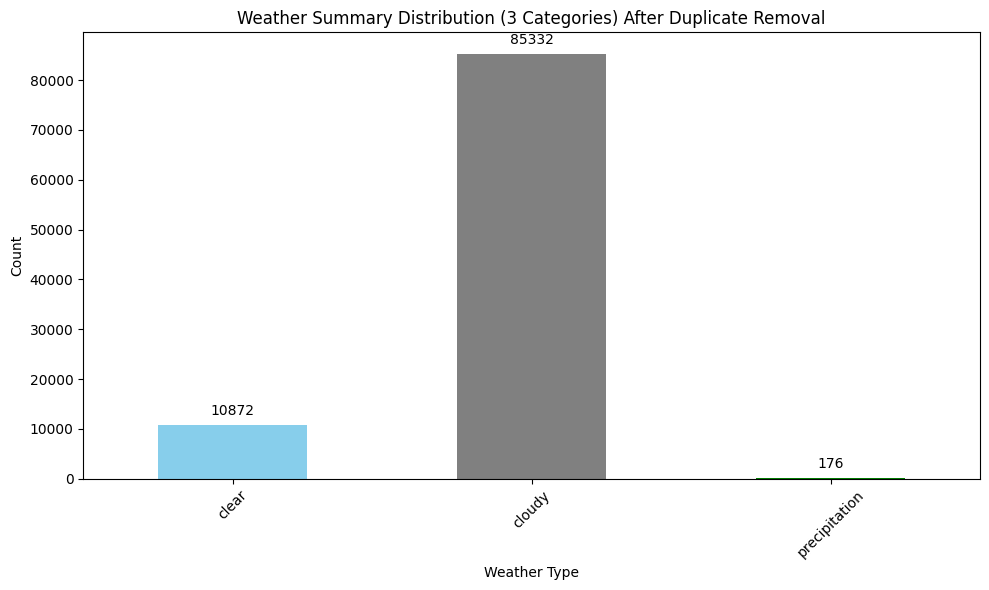

In [9]:
# Visualize the cleaned data distribution (using text labels)
plt.figure(figsize=(10,6))
ax = df_cleaned['Simple_Summary'].value_counts().reindex(['clear', 'cloudy', 'precipitation']).plot(kind='bar', color=['skyblue', 'gray', 'green'])

# Add value labels on bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
               (p.get_x() + p.get_width()/2., p.get_height()),
               ha='center', va='center',
               xytext=(0, 10),
               textcoords='offset points')

plt.title('Weather Summary Distribution (3 Categories) After Duplicate Removal')
plt.xlabel('Weather Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


USING SMOTE


Class distribution after SMOTE:
Simple_Summary_Class
0    30000
1    30000
2     5000
Name: count, dtype: int64


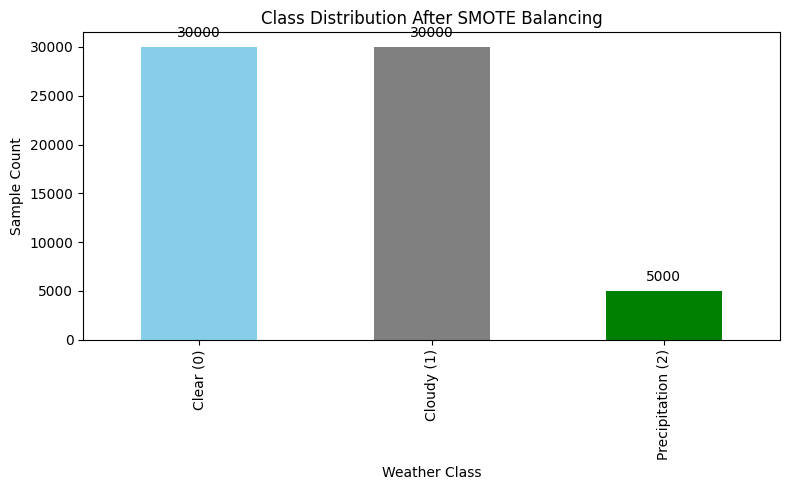

In [10]:
# Split features and labels
X = df_cleaned.drop(['Simple_Summary', 'Simple_Summary_Class'], axis=1)
y = df_cleaned['Simple_Summary_Class']

# Combine for easier handling
df_combined = pd.concat([X, y], axis=1)

# Step 1: Downsample class 1 (Cloudy) from 85,332 to 30,000 (SMOTE cannot downsample)
df_cloudy = df_combined[df_combined['Simple_Summary_Class'] == 1]
df_cloudy_downsampled = resample(df_cloudy,
                                 replace=False,
                                 n_samples=30000,
                                 random_state=42)

# Step 2: Keep all original Clear (0) and Precipitation (2)
df_clear = df_combined[df_combined['Simple_Summary_Class'] == 0]  # 10872
df_precip = df_combined[df_combined['Simple_Summary_Class'] == 2]  # 176

# Step 3: Combine these for SMOTE
df_for_smote = pd.concat([df_clear, df_precip, df_cloudy_downsampled])
X_smote = df_for_smote.drop('Simple_Summary_Class', axis=1)
y_smote = df_for_smote['Simple_Summary_Class']

# Step 4: Apply SMOTE to achieve Clear = 30,000 and Precip = 3,000
# Define sampling_strategy to control final class counts
smote = SMOTE(sampling_strategy={0: 30000, 2: 5000}, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_smote, y_smote)

# Final dataset
print("\nClass distribution after SMOTE:")
print(pd.Series(y_train_resampled).value_counts().sort_index())  # Should be 0:30k, 1:30k, 2:3k

# Optional: Visualization
plt.figure(figsize=(8, 5))
ax = pd.Series(y_train_resampled).value_counts().sort_index().plot(kind='bar', color=['skyblue', 'gray', 'green'])

# Annotate values
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')

plt.title('Class Distribution After SMOTE Balancing')
plt.xlabel('Weather Class')
plt.ylabel('Sample Count')
plt.xticks(ticks=[0, 1, 2], labels=['Clear (0)', 'Cloudy (1)', 'Precipitation (2)'])
plt.tight_layout()
plt.show()


REMOVING OUTLIERS

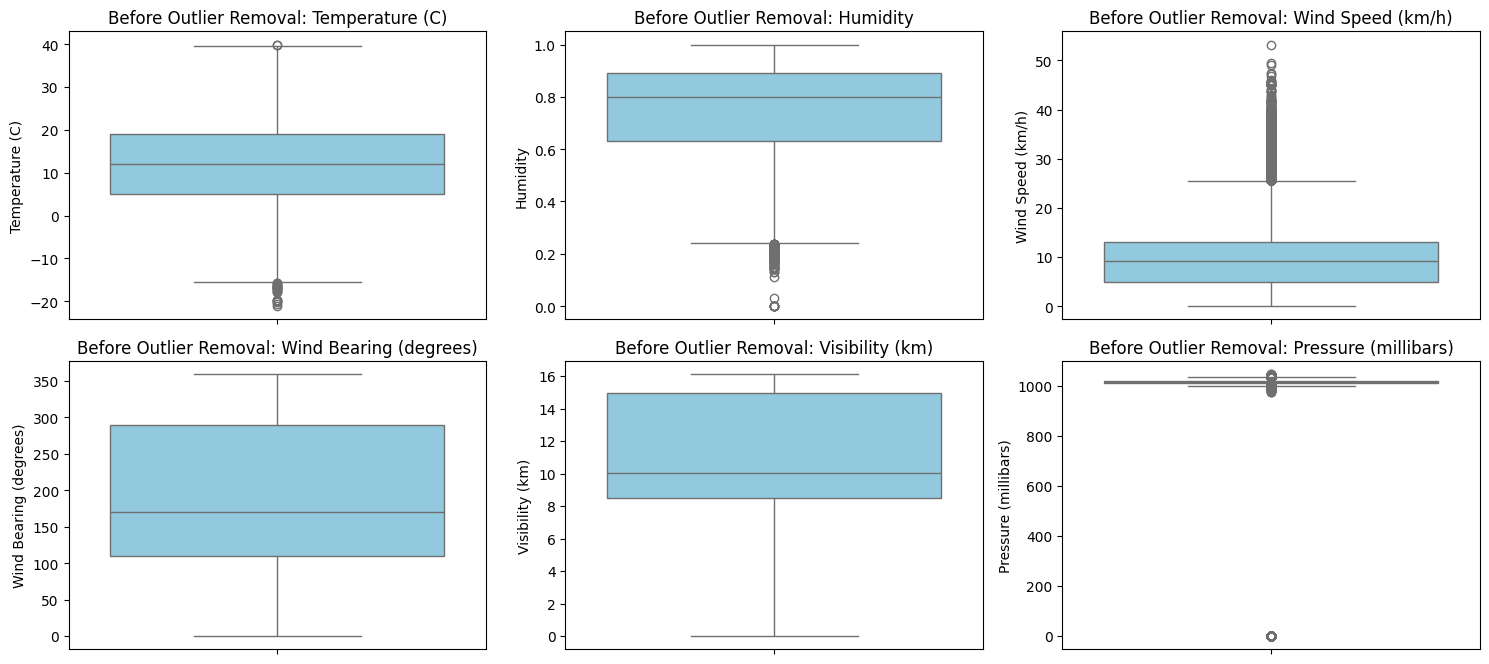

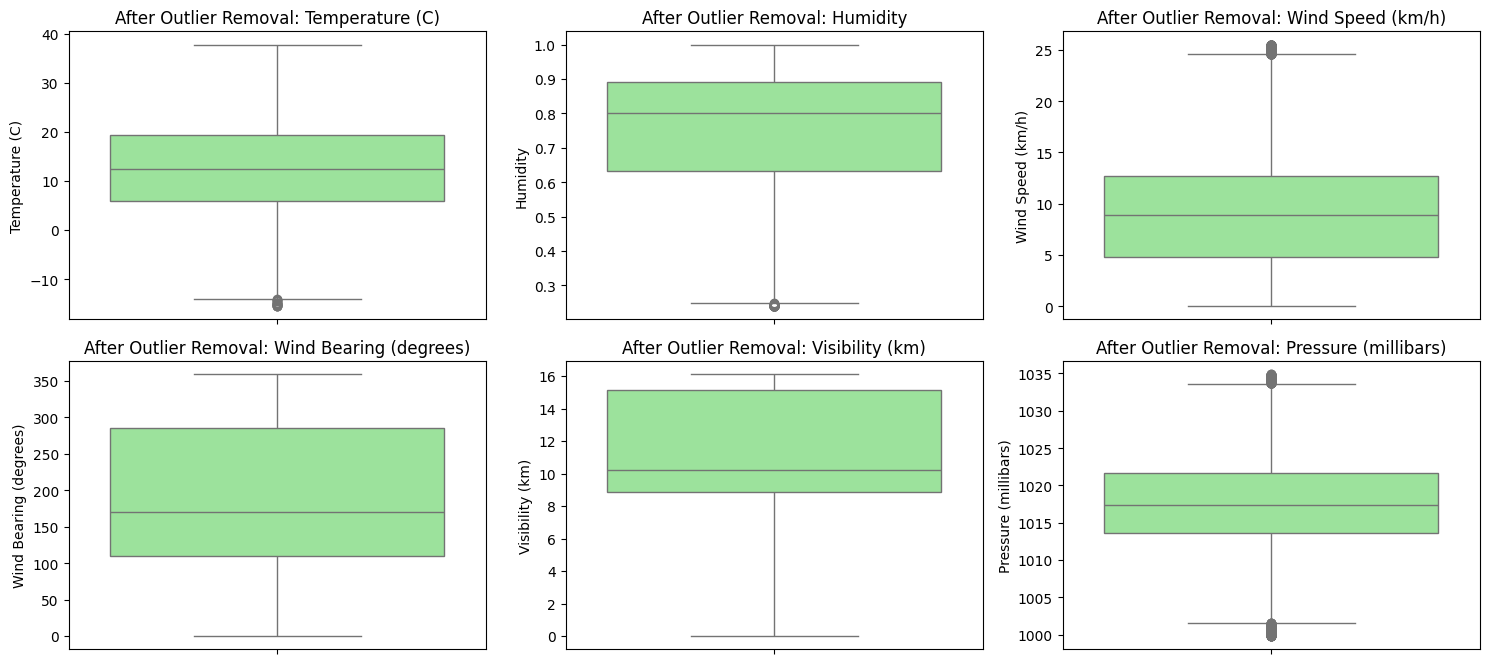


Original shape: (65000, 6)
After outlier removal: (58976, 6)


In [11]:
# ========== STEP 1: Visualize Before Outlier Removal ==========
# Select only numerical columns
numeric_cols = X_train_resampled.select_dtypes(include=['float64', 'int64']).columns

# Plot boxplots for each feature before removing outliers
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(3, 3, i+1)
    sns.boxplot(y=X_train_resampled[col], color='skyblue')
    plt.title(f'Before Outlier Removal: {col}')
    plt.tight_layout()
plt.show()

# ========== STEP 2: Remove Outliers Using IQR ==========
# Create a copy to avoid modifying the original
X_resampled_clean = X_train_resampled.copy()
y_resampled_clean = y_train_resampled.copy()

for col in numeric_cols:
    Q1 = X_resampled_clean[col].quantile(0.25)
    Q3 = X_resampled_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Create a mask for rows within the bounds
    mask = (X_resampled_clean[col] >= lower_bound) & (X_resampled_clean[col] <= upper_bound)
    
    # Apply mask to both features and target
    X_resampled_clean = X_resampled_clean[mask]
    y_resampled_clean = y_resampled_clean[mask]

# ========== STEP 3: Visualize After Outlier Removal ==========
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(3, 3, i+1)
    sns.boxplot(y=X_resampled_clean[col], color='lightgreen')
    plt.title(f'After Outlier Removal: {col}')
    plt.tight_layout()
plt.show()

# Optional: Report how many records were removed
print(f"\nOriginal shape: {X_train_resampled.shape}")
print(f"After outlier removal: {X_resampled_clean.shape}")


STANDARDIZING THE DATA

In [12]:
# Step 1: Split the data (after SMOTE + outlier removal)
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled_clean, y_resampled_clean, test_size=0.3, random_state=42, stratify=y_resampled_clean
)

# Step 2: Initialize and fit the scaler only on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Step 3: Transform the test data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Step 4 (Optional): Convert back to DataFrames
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

# Confirm mean ~ 0 and std ~ 1 on training data
print("\nStandardized Training Data Summary:")
print(X_train_scaled_df.describe().loc[['mean', 'std']])

# Save the fitted scaler to disk for later use
joblib.dump(scaler, 'scaler.pkl')
print("Scaler saved to scaler.pkl")




Standardized Training Data Summary:
      Temperature (C)      Humidity  Wind Speed (km/h)  \
mean    -6.084269e-17  1.839050e-16      -1.008594e-16   
std      1.000012e+00  1.000012e+00       1.000012e+00   

      Wind Bearing (degrees)  Visibility (km)  Pressure (millibars)  
mean            1.135960e-17    -4.665180e-16         -2.342867e-14  
std             1.000012e+00     1.000012e+00          1.000012e+00  
Scaler saved to scaler.pkl


# **APPLYING KNN**

### **MODEL 1**


🔍 Evaluation Metrics for K=2:
Train Accuracy: 0.8758
Test Accuracy : 0.7776

📄 Classification Report:
               precision    recall  f1-score   support

        Clear       0.69      0.95      0.80      8044
       Cloudy       0.91      0.58      0.71      8218
Precipitation       0.94      0.96      0.95      1431

     accuracy                           0.78     17693
    macro avg       0.85      0.83      0.82     17693
 weighted avg       0.81      0.78      0.77     17693



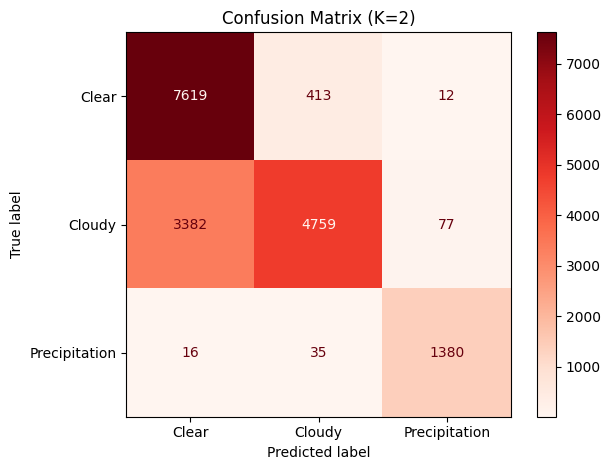

Model saved to knn_model.pkl


In [13]:
def knn_model1(X_train_scaled, X_test_scaled, y_train, y_test):
    k1 = 2
    knn = KNeighborsClassifier(n_neighbors=k1)
    knn.fit(X_train_scaled, y_train)

    y_test_pred = knn.predict(X_test_scaled)
    y_train_pred = knn.predict(X_train_scaled)

    knn_test_acc1 = accuracy_score(y_test, y_test_pred)
    knn_train_acc1 = accuracy_score(y_train, y_train_pred)
    conf_mat = confusion_matrix(y_test, y_test_pred)

    print(f"\n🔍 Evaluation Metrics for K={k1}:")
    print(f"Train Accuracy: {knn_train_acc1:.4f}")
    print(f"Test Accuracy : {knn_test_acc1:.4f}")

    target_names = ['Clear', 'Cloudy', 'Precipitation']
    print("\n📄 Classification Report:")
    print(classification_report(y_test, y_test_pred, target_names=target_names))

    disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat, display_labels=target_names)
    disp.plot(cmap='Reds', values_format='d')
    plt.title(f'Confusion Matrix (K={k1})')
    plt.tight_layout()
    plt.show()

    return knn, k1, knn_train_acc1, knn_test_acc1

# Train and get the model
knn, k1, knn_train_acc1, knn_test_acc1 = knn_model1(X_train_scaled, X_test_scaled, y_train, y_test)

# Save the trained model
joblib_file = "knn_model.pkl"
joblib.dump(knn, joblib_file)
print(f"Model saved to {joblib_file}")



### **MODEL 2**


🔍 Evaluation Metrics for K=5:
Train Accuracy: 0.8533
Test Accuracy : 0.7829

📄 Classification Report:
               precision    recall  f1-score   support

        Clear       0.73      0.86      0.79      8044
       Cloudy       0.83      0.67      0.75      8218
Precipitation       0.87      0.98      0.92      1431

     accuracy                           0.78     17693
    macro avg       0.81      0.84      0.82     17693
 weighted avg       0.79      0.78      0.78     17693



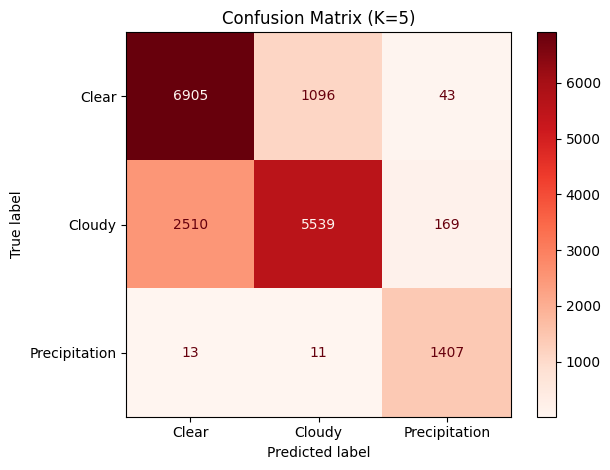

In [14]:
def knn_model2(X_train_scaled, X_test_scaled, y_train, y_test):
    k2 = 5
    knn = KNeighborsClassifier(n_neighbors=k2)
    knn.fit(X_train_scaled, y_train)

    # ====== STEP 2: Predict on test and train set ======
    y_test_pred = knn.predict(X_test_scaled)
    y_train_pred = knn.predict(X_train_scaled)

    # ====== STEP 3: Evaluation Metrics ======
    knn_test_acc2 = accuracy_score(y_test, y_test_pred)
    knn_train_acc2 = accuracy_score(y_train, y_train_pred)
    conf_mat = confusion_matrix(y_test, y_test_pred)

    # ====== PRINT TRAIN/TEST ACCURACY ======
    print(f"\n🔍 Evaluation Metrics for K={k2}:")
    print(f"Train Accuracy: {knn_train_acc2:.4f}")
    print(f"Test Accuracy : {knn_test_acc2:.4f}")

    # ====== STEP 4: Classification Report ======
    target_names = ['Clear', 'Cloudy', 'Precipitation']
    print("\n📄 Classification Report:")
    print(classification_report(y_test, y_test_pred, target_names=target_names))

    # ====== STEP 5: Confusion Matrix ======
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat,
                                  display_labels=target_names)
    disp.plot(cmap='Reds', values_format='d')
    plt.title(f'Confusion Matrix (K={k2})')
    plt.tight_layout()
    plt.show()
    return k2, knn_train_acc2, knn_test_acc2
k2, knn_train_acc2, knn_test_acc2 = knn_model2(X_train_scaled, X_test_scaled, y_train, y_test)

### **MODEL 3**


🔍 Evaluation Metrics for K=15:
Train Accuracy: 0.7888
Test Accuracy : 0.7600

📄 Classification Report:
               precision    recall  f1-score   support

        Clear       0.72      0.84      0.77      8044
       Cloudy       0.81      0.65      0.72      8218
Precipitation       0.80      0.98      0.88      1431

     accuracy                           0.76     17693
    macro avg       0.78      0.82      0.79     17693
 weighted avg       0.77      0.76      0.76     17693



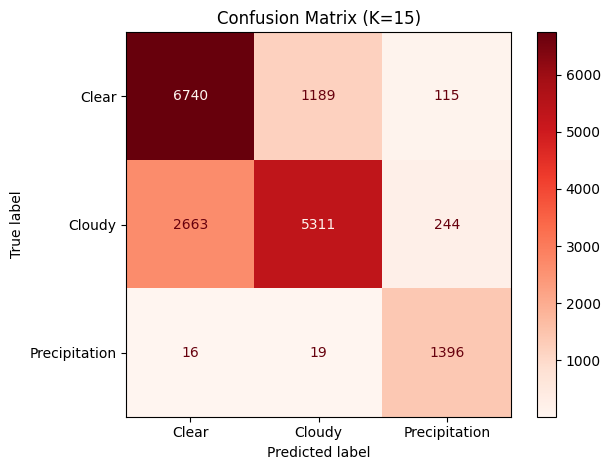

In [15]:
def knn_model3(X_train_scaled, X_test_scaled, y_train, y_test):
    k3 = 15
    knn = KNeighborsClassifier(n_neighbors=k3)
    knn.fit(X_train_scaled, y_train)

    # ====== STEP 2: Predict on test and train set ======
    y_test_pred = knn.predict(X_test_scaled)
    y_train_pred = knn.predict(X_train_scaled)

    # ====== STEP 3: Evaluation Metrics ======
    knn_test_acc3 = accuracy_score(y_test, y_test_pred)
    knn_train_acc3 = accuracy_score(y_train, y_train_pred)
    conf_mat = confusion_matrix(y_test, y_test_pred)

    # ====== PRINT TRAIN/TEST ACCURACY ======
    print(f"\n🔍 Evaluation Metrics for K={k3}:")
    print(f"Train Accuracy: {knn_train_acc3:.4f}")
    print(f"Test Accuracy : {knn_test_acc3:.4f}")

    # ====== STEP 4: Classification Report ======
    target_names = ['Clear', 'Cloudy', 'Precipitation']
    print("\n📄 Classification Report:")
    print(classification_report(y_test, y_test_pred, target_names=target_names))

    # ====== STEP 5: Confusion Matrix ======
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat,
                                  display_labels=target_names)
    disp.plot(cmap='Reds', values_format='d')
    plt.title(f'Confusion Matrix (K={k3})')
    plt.tight_layout()
    plt.show()
    return k3, knn_train_acc3, knn_test_acc3
k3, knn_train_acc3, knn_test_acc3 = knn_model3(X_train_scaled, X_test_scaled, y_train, y_test)



PRINTING ACCURACIES THROUGH GRAPH

In [ ]:
# ====== STEP 6: Accuracy vs K Graph with Train/Test Accuracy ======
k_values = list(range(1, 21))
train_accuracies = []
test_accuracies = []

print("\n📊 Train vs Test Accuracy for different K values:")
print("K\tTrain Accuracy\tTest Accuracy")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    y_train_pred = knn.predict(X_train_scaled)
    y_test_pred = knn.predict(X_test_scaled)
    
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    
    print(f"{k}\t{train_acc:.4f}\t\t{test_acc:.4f}")

# Plotting Accuracy vs. K
plt.figure(figsize=(10, 6))
sns.lineplot(x=k_values, y=train_accuracies, marker='o', label='Train Accuracy', color='green')
sns.lineplot(x=k_values, y=test_accuracies, marker='o', label='Test Accuracy', color='blue')
plt.title('KNN Train vs Test Accuracy vs. K Value')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show() 


📊 Comparison of KNN Models:
K	Train Accuracy	Test Accuracy
2	0.8758		0.7776
5	0.8533		0.7829
15	0.7888		0.7600


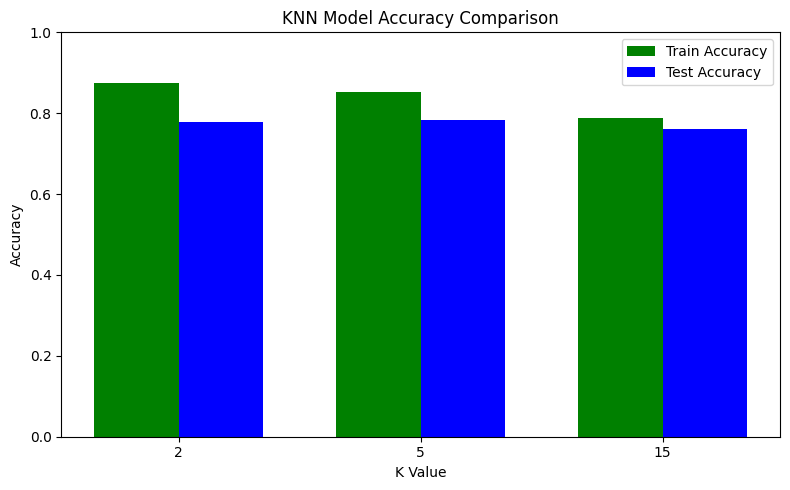

In [16]:
# Store K values and corresponding accuracies
k_values = [k1, k2, k3]
train_accuracies = [knn_train_acc1, knn_train_acc2, knn_train_acc3]   # Replace with actual outputs from your models
test_accuracies = [knn_test_acc1, knn_test_acc2, knn_test_acc3]    # Replace with actual outputs from your models

# Print the comparison in a table
print("\n📊 Comparison of KNN Models:")
print("K\tTrain Accuracy\tTest Accuracy")
for k, train_acc, test_acc in zip(k_values, train_accuracies, test_accuracies):
    print(f"{k}\t{train_acc:.4f}\t\t{test_acc:.4f}")

# Plotting bar chart
plt.figure(figsize=(8, 5))
x = range(len(k_values))
bar_width = 0.35

plt.bar(x, train_accuracies, width=bar_width, label='Train Accuracy', color='green')
plt.bar([i + bar_width for i in x], test_accuracies, width=bar_width, label='Test Accuracy', color='blue')

plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN Model Accuracy Comparison')
plt.xticks([i + bar_width / 2 for i in x], k_values)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


# **APPLYING LOGISTIC REGRESSION**

### **MODEL 1**

c:\Users\HAJI LAPTOP\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



=== Logistic Regression Evaluation ===
Train Accuracy: 0.6112
Test Accuracy: 0.6187

Classification Report:
               precision    recall  f1-score   support

        Clear       0.65      0.66      0.66      8044
       Cloudy       0.60      0.62      0.61      8218
Precipitation       0.53      0.37      0.44      1431

     accuracy                           0.62     17693
    macro avg       0.59      0.55      0.57     17693
 weighted avg       0.62      0.62      0.62     17693



<Figure size 600x500 with 0 Axes>

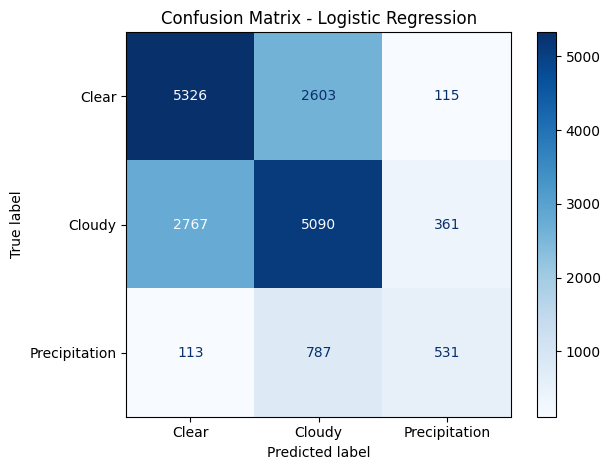

Model saved to logistic_regression_model.pkl


In [17]:
def log_regression1():
    log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
    log_model.fit(X_train_scaled, y_train)

    y_pred = log_model.predict(X_test_scaled)
    train_preds = log_model.predict(X_train_scaled)
    lr_train_accuracy1 = accuracy_score(y_train, train_preds)
    lr_test_accuracy1 = accuracy_score(y_test, y_pred)

    print("\n=== Logistic Regression Evaluation ===")
    print(f"Train Accuracy: {lr_train_accuracy1:.4f}")
    print(f"Test Accuracy: {lr_test_accuracy1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Clear', 'Cloudy', 'Precipitation']))

    plt.figure(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Clear', 'Cloudy', 'Precipitation'], cmap='Blues')
    plt.title("Confusion Matrix - Logistic Regression")
    plt.tight_layout()
    plt.show()

    return log_model, lr_train_accuracy1, lr_test_accuracy1

# Train model and get results
log_model, lr_train_accuracy1, lr_test_accuracy1 = log_regression1()

# Save the trained model
joblib_file = "logistic_regression_model.pkl"
joblib.dump(log_model, joblib_file)
print(f"Model saved to {joblib_file}")

# To load later:
# loaded_log_model = joblib.load(joblib_file)


### **MODEL 2**

c:\Users\HAJI LAPTOP\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1281: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(



=== Logistic Regression Evaluation with Custom Hyperparameters ===
Train Accuracy     : 0.6076
Test Accuracy      : 0.6128

Classification Report:
               precision    recall  f1-score   support

        Clear       0.64      0.69      0.66      8044
       Cloudy       0.60      0.61      0.60      8218
Precipitation       0.51      0.22      0.30      1431

     accuracy                           0.61     17693
    macro avg       0.58      0.50      0.52     17693
 weighted avg       0.61      0.61      0.60     17693



<Figure size 600x500 with 0 Axes>

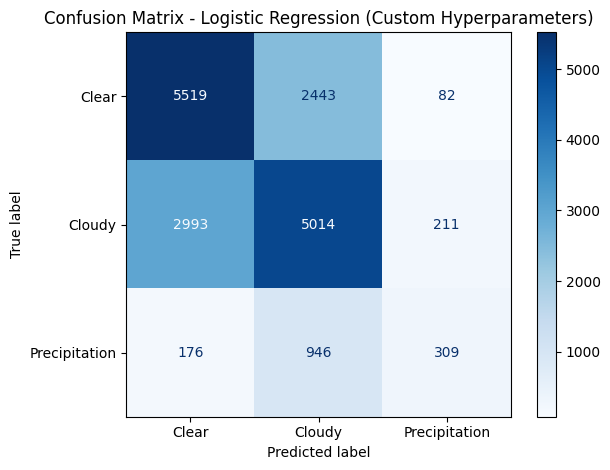

In [18]:
# Step 3: Initialize Logistic Regression Model with different hyperparameters
def log_regression2():
    log_model1 = LogisticRegression(
        multi_class='ovr',            # One-vs-Rest strategy
        solver='saga',                # Stochastic Average Gradient solver (supports L1)
        penalty='l1',                 # L1 regularization (sparse features)
        C=0.5,                        # Regularization strength (lower = stronger penalty)
        max_iter=2000,                # Increase max iterations to ensure convergence
        random_state=42               # For reproducibility
    )

    # Step 4: Train the model
    log_model1.fit(X_train_scaled, y_train)

    # Step 5: Predictions
    y_pred = log_model1.predict(X_test_scaled)

    # Step 6: Evaluation
    train_preds = log_model1.predict(X_train_scaled)
    lr_train_accuracy2 = accuracy_score(y_train, train_preds)
    lr_test_accuracy2 = accuracy_score(y_test, y_pred)

    # Print metrics
    print("\n=== Logistic Regression Evaluation with Custom Hyperparameters ===")
    print(f"Train Accuracy     : {lr_train_accuracy2:.4f}")
    print(f"Test Accuracy      : {lr_test_accuracy2:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Clear', 'Cloudy', 'Precipitation']))

    # Step 7: Confusion Matrix
    plt.figure(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['Clear', 'Cloudy', 'Precipitation'],
        cmap='Blues'
    )
    plt.title("Confusion Matrix - Logistic Regression (Custom Hyperparameters)")
    plt.tight_layout()
    plt.show()
    return log_model1, lr_train_accuracy2, lr_test_accuracy2
log_model1, lr_train_accuracy2, lr_test_accuracy2 = log_regression2()

### **MODEL 3** 

c:\Users\HAJI LAPTOP\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



=== Logistic Regression Evaluation with NEW Hyperparameters ===
Train Accuracy     : 0.6112
Test Accuracy      : 0.6186

Classification Report:
               precision    recall  f1-score   support

        Clear       0.65      0.66      0.66      8044
       Cloudy       0.60      0.62      0.61      8218
Precipitation       0.53      0.37      0.44      1431

     accuracy                           0.62     17693
    macro avg       0.59      0.55      0.57     17693
 weighted avg       0.62      0.62      0.62     17693



<Figure size 600x500 with 0 Axes>

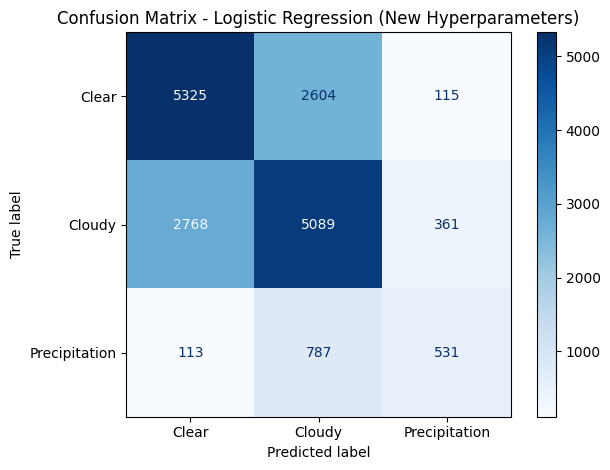

In [19]:
# Step 3: Initialize Logistic Regression Model with NEW hyperparameters
def log_regression3():
    log_model2 = LogisticRegression(
        multi_class='multinomial',   # Better for true multiclass probability modeling
        solver='newton-cg',          # Newton's method – good for multinomial + l2
        penalty='l2',                # L2 regularization (default)
        C=1.5,                       # Weaker regularization (default is 1.0)
        max_iter=3000,               # Enough for convergence in most cases
        random_state=42              # Reproducibility
    )

    # Step 4: Train the model
    log_model2.fit(X_train_scaled, y_train)

    # Step 5: Predictions
    y_pred = log_model2.predict(X_test_scaled)

    # Step 6: Evaluation
    train_preds = log_model2.predict(X_train_scaled)
    lr_train_accuracy3 = accuracy_score(y_train, train_preds)
    lr_test_accuracy3 = accuracy_score(y_test, y_pred)

    # Print metrics
    print("\n=== Logistic Regression Evaluation with NEW Hyperparameters ===")
    print(f"Train Accuracy     : {lr_train_accuracy3:.4f}")
    print(f"Test Accuracy      : {lr_test_accuracy3:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Clear', 'Cloudy', 'Precipitation']))

    # Step 7: Confusion Matrix
    plt.figure(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['Clear', 'Cloudy', 'Precipitation'],
        cmap='Blues'
    )
    plt.title("Confusion Matrix - Logistic Regression (New Hyperparameters)")
    plt.tight_layout()
    plt.show()
    return log_model2, lr_train_accuracy3, lr_test_accuracy3
log_model2, lr_train_accuracy3, lr_test_accuracy3=log_regression3()


📊 Logistic Regression Model Accuracy Comparison
Model			Train Accuracy	Test Accuracy
Model 1: Default        0.6112		0.6187
Model 2: L1 + OVR       0.6076		0.6128
Model 3: L2 + Newton-CG 0.6112		0.6186


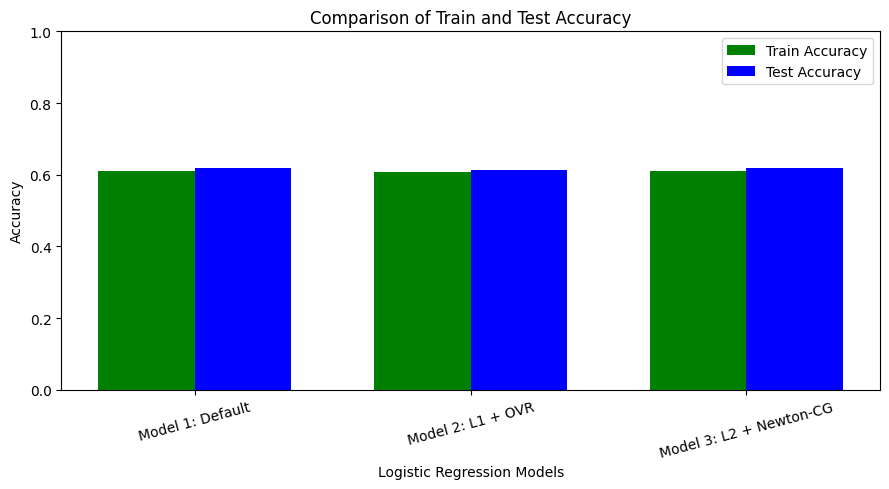

In [ ]:
# === Step 1: Accuracy values for each model ===
# Replace these with actual values from your model outputs
model_names = ["Model 1: Default", "Model 2: L1 + OVR", "Model 3: L2 + Newton-CG"]
train_accuracies = [lr_train_accuracy1, lr_train_accuracy2, lr_train_accuracy3]  
test_accuracies = [lr_test_accuracy1, lr_test_accuracy2, lr_test_accuracy3]  

# === Step 2: Print as a table ===
print("\n📊 Logistic Regression Model Accuracy Comparison")
print("Model\t\t\tTrain Accuracy\tTest Accuracy")
for name, train_acc, test_acc in zip(model_names, train_accuracies, test_accuracies):
    print(f"{name:<24}{train_acc:.4f}\t\t{test_acc:.4f}")

# === Step 3: Bar Chart for Visual Comparison ===
x = range(len(model_names))
bar_width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x, train_accuracies, width=bar_width, label='Train Accuracy', color='green')
plt.bar([i + bar_width for i in x], test_accuracies, width=bar_width, label='Test Accuracy', color='blue')

plt.xticks([i + bar_width / 2 for i in x], model_names, rotation=15)
plt.ylim(0, 1)
plt.xlabel("Logistic Regression Models")
plt.ylabel("Accuracy")
plt.title("Comparison of Train and Test Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


# **Artifical Neural Network**

In [21]:
# Convert y_train and y_test to one-hot encoded format
y_train_one_hot = to_categorical(y_train, num_classes=3)
y_test_one_hot = to_categorical(y_test, num_classes=3)

ANN = models.Sequential()
ANN.add(layers.Input(shape=(6,)))  # Assuming you have 6 features
ANN.add(layers.Dense(units=100, activation="relu", kernel_regularizer=regularizers.l2(0.01)))  # L2 regularization
ANN.add(layers.Dense(units=100, activation="relu"))
ANN.add(layers.Dense(units=3, activation="softmax"))  # Output layer for 3 classes
ANN.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │           700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           303 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,103 (43.37 KB)

 Trainable params: 11,103 (43.37 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
ANN.compile(loss="categorical_crossentropy", 
                optimizer="rmsprop", 
                metrics=["accuracy"])

### **Epochs= 20 & Batch_size= 100**

553/553 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7588 - loss: 0.5175
Test loss is 0.517
Test accuracy is 75.9%
1291/1291 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7834 - loss: 0.4766
Train loss is 0.477
Train accuracy is 78.3%
553/553 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

=== ANN Evaluation ===
Train Accuracy: 0.7834
Test Accuracy: 0.7588

Classification Report:
               precision    recall  f1-score   support

        Clear       0.72      0.79      0.75      8044
       Cloudy       0.77      0.69      0.73      8218
Precipitation       0.91      0.98      0.94      1431

     accuracy                           0.76     17693
    macro avg       0.80      0.82      0.81     17693
 weighted avg       0.76      0.76      0.76     17693



<Figure size 600x500 with 0 Axes>

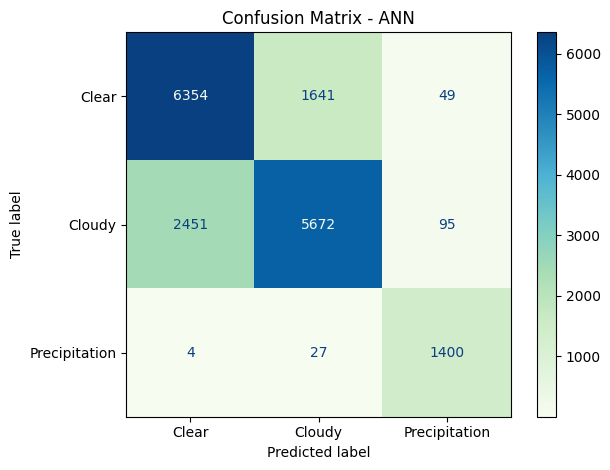

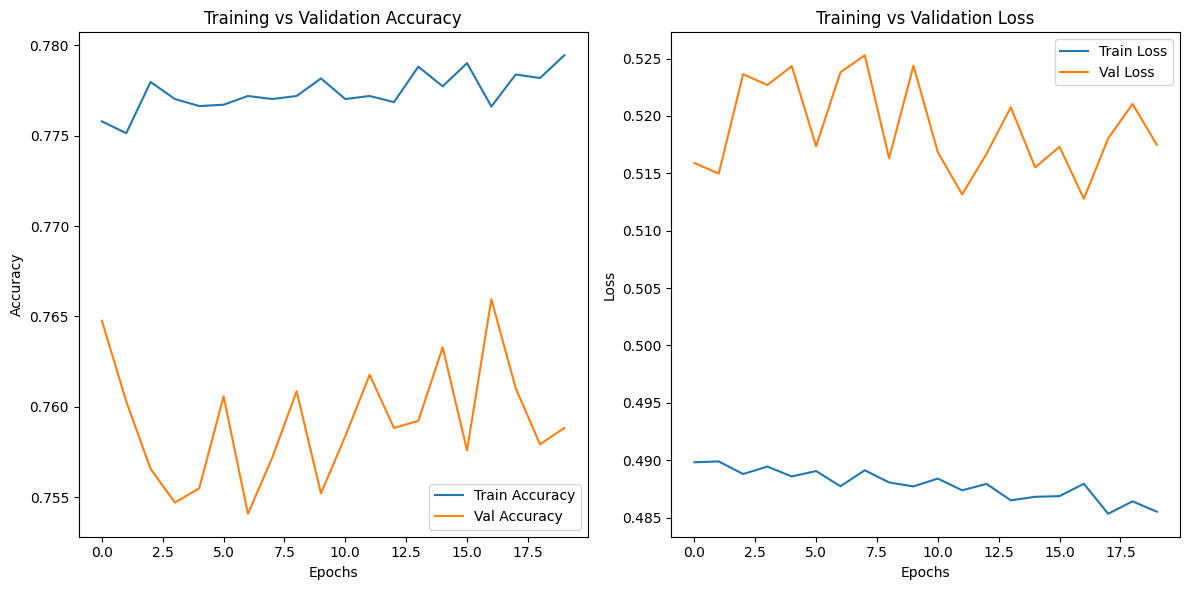

In [27]:
# Train the ANN model
def ann(ANN, X_train_scaled, y_train_one_hot, X_test_scaled, y_test_one_hot):
    # Train the ANN model
    history = ANN.fit(X_train_scaled, 
                      y_train_one_hot, 
                      epochs=20,
                      verbose=0,
                      batch_size=100,
                      validation_data=(X_test_scaled, y_test_one_hot))

    # Evaluate the ANN model on the test data
    test_loss, test_accuracy = ANN.evaluate(X_test_scaled, y_test_one_hot)
    print(f'Test loss is {test_loss:0.3}')
    print(f'Test accuracy is {test_accuracy:0.1%}')

    # Evaluate the ANN model on the train data
    train_loss, train_accuracy = ANN.evaluate(X_train_scaled, y_train_one_hot)
    print(f'Train loss is {train_loss:0.3}')
    print(f'Train accuracy is {train_accuracy:0.1%}')

    # Get predictions from the ANN model on the test data
    ann_preds = ANN.predict(X_test_scaled)

    # Convert the one-hot encoded predictions to class labels
    ann_preds_class = ann_preds.argmax(axis=1)
    y_test_class = y_test_one_hot.argmax(axis=1)  # Convert the one-hot encoded true labels to class labels

    # Calculate accuracy, precision, recall, and F1-score
    test_accuracy_ann = accuracy_score(y_test_class, ann_preds_class)
    print("\n=== ANN Evaluation ===")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Test Accuracy: {test_accuracy_ann:.4f}")

    # Print the classification report for the ANN model
    print("\nClassification Report:")
    print(classification_report(y_test_class, ann_preds_class, target_names=['Clear', 'Cloudy', 'Precipitation']))

    # Display Confusion Matrix for ANN
    plt.figure(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test_class, ann_preds_class, display_labels=['Clear', 'Cloudy', 'Precipitation'], cmap='GnBu')
    plt.title("Confusion Matrix - ANN")
    plt.tight_layout()
    plt.show()

    # Plot Training and Validation Accuracy
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title('Training vs Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot Training and Validation Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title('Training vs Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return ANN, history, {"train_acc": train_accuracy, "test_acc": test_accuracy}
ANN, history, results1 = ann(ANN, X_train_scaled, y_train_one_hot, X_test_scaled, y_test_one_hot)



### **Epochs= 50 & Batch_size= 130**

553/553 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7652 - loss: 0.5081
Test loss is 0.508
Test accuracy is 76.5%
1291/1291 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7934 - loss: 0.4610
Train loss is 0.461
Train accuracy is 79.3%
553/553 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

=== ANN Evaluation ===
Train Accuracy: 0.7934
Test Accuracy: 0.7652

Classification Report:
               precision    recall  f1-score   support

        Clear       0.72      0.81      0.76      8044
       Cloudy       0.79      0.68      0.73      8218
Precipitation       0.93      0.98      0.96      1431

     accuracy                           0.77     17693
    macro avg       0.81      0.82      0.82     17693
 weighted avg       0.77      0.77      0.76     17693



<Figure size 600x500 with 0 Axes>

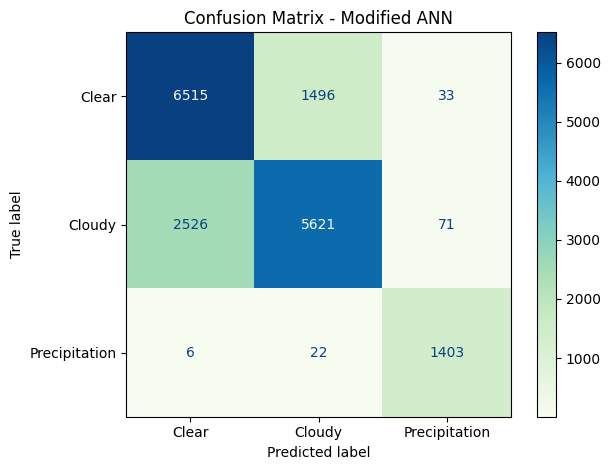

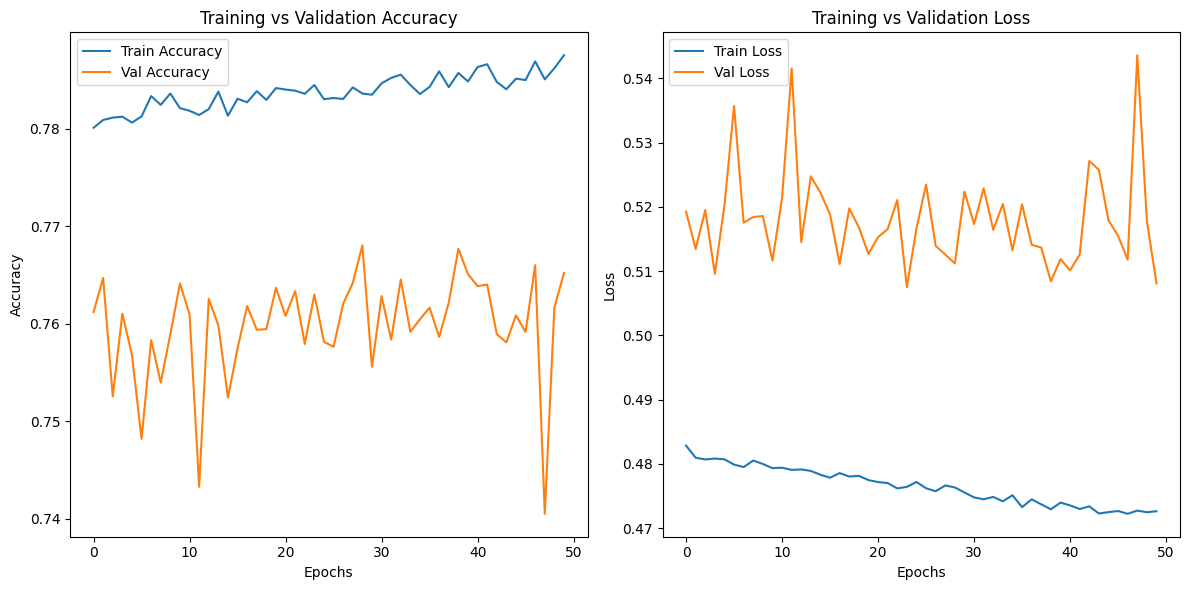

In [28]:
def ann1(ANN, X_train_scaled, y_train_one_hot, X_test_scaled, y_test_one_hot):
    # Train the modified ANN model with updated hyperparameters
    history1 = ANN.fit(X_train_scaled, 
                       y_train_one_hot, 
                       epochs=50,
                       verbose=0,
                       batch_size=130, 
                       validation_data=(X_test_scaled, y_test_one_hot)) 

    # Evaluate the model on the test data
    test_loss2, test_accuracy2 = ANN.evaluate(X_test_scaled, y_test_one_hot)
    print(f'Test loss is {test_loss2:0.3}')
    print(f'Test accuracy is {test_accuracy2:0.1%}')

    # Evaluate the model on the train data
    train_loss2, train_accuracy2 = ANN.evaluate(X_train_scaled, y_train_one_hot)
    print(f'Train loss is {train_loss2:0.3}')
    print(f'Train accuracy is {train_accuracy2:0.1%}')

    # Get predictions from the ANN model on the test data
    ann_preds = ANN.predict(X_test_scaled)

    # Convert the one-hot encoded predictions to class labels
    ann_preds_class = ann_preds.argmax(axis=1)
    y_test_class = y_test_one_hot.argmax(axis=1)  # Convert the one-hot encoded true labels to class labels

    # Calculate accuracy, precision, recall, and F1-score
    test_accuracy_ann = accuracy_score(y_test_class, ann_preds_class)
    print("\n=== ANN Evaluation ===")
    print(f"Train Accuracy: {train_accuracy2:.4f}")
    print(f"Test Accuracy: {test_accuracy_ann:.4f}")

    # Print the classification report for the modified ANN model
    print("\nClassification Report:")
    print(classification_report(y_test_class, ann_preds_class, target_names=['Clear', 'Cloudy', 'Precipitation']))

    # Display Confusion Matrix for the modified ANN model
    plt.figure(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test_class, ann_preds_class, display_labels=['Clear', 'Cloudy', 'Precipitation'], cmap='GnBu')
    plt.title("Confusion Matrix - Modified ANN")
    plt.tight_layout()
    plt.show()

    # Plot Training and Validation Accuracy
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history1.history['accuracy'], label='Train Accuracy')
    plt.plot(history1.history['val_accuracy'], label='Val Accuracy')
    plt.title('Training vs Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot Training and Validation Loss
    plt.subplot(1, 2, 2)
    plt.plot(history1.history['loss'], label='Train Loss')
    plt.plot(history1.history['val_loss'], label='Val Loss')
    plt.title('Training vs Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Return the trained model and history object
    return ANN, history1, {"train_acc": train_accuracy2, "test_acc": test_accuracy2}
ANN, history1, results2 = ann1(ANN, X_train_scaled, y_train_one_hot, X_test_scaled, y_test_one_hot)


### **Epochs= 80 & Batch_size= 150**

553/553 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7606 - loss: 0.5277
Test loss is 0.528
Test accuracy is 76.1%
1291/1291 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7883 - loss: 0.4710
Train loss is 0.471
Train accuracy is 78.8%
553/553 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

=== ANN Evaluation ===
Train Accuracy: 0.7883
Test Accuracy: 0.7606

Classification Report:
               precision    recall  f1-score   support

        Clear       0.69      0.88      0.77      8044
       Cloudy       0.84      0.61      0.71      8218
Precipitation       0.91      0.98      0.94      1431

     accuracy                           0.76     17693
    macro avg       0.81      0.82      0.81     17693
 weighted avg       0.78      0.76      0.76     17693



<Figure size 600x500 with 0 Axes>

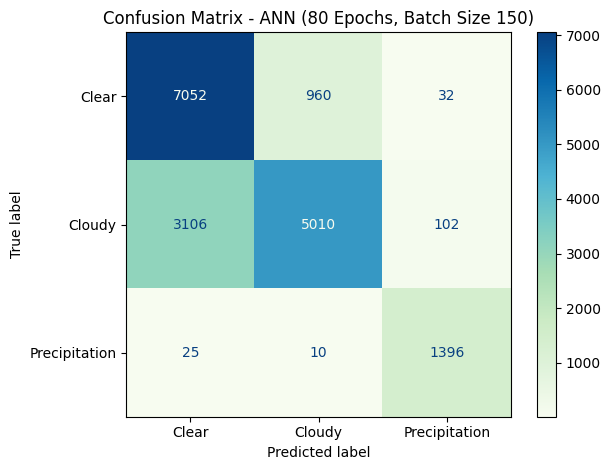

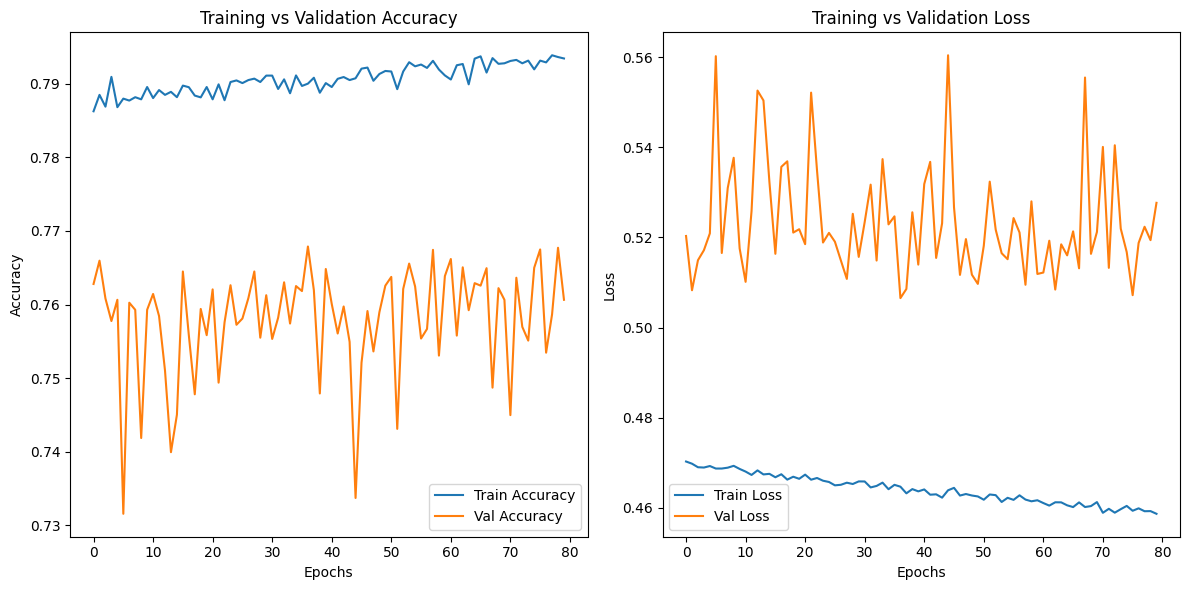

ANN model saved to 'ann_model.h5'


In [ ]:
# Train the ANN model with the new hyperparameters (80 epochs, batch size 150)
def ann2(ANN, X_train_scaled, y_train_one_hot, X_test_scaled, y_test_one_hot):
    # Train the ANN model with the new hyperparameters (80 epochs, batch size 150)
    history2 = ANN.fit(X_train_scaled,
                       y_train_one_hot,
                       epochs=80,
                       verbose=0,
                       batch_size=150,
                       validation_data=(X_test_scaled, y_test_one_hot))

    # Evaluate the model on the test data
    test_loss2, test_accuracy2 = ANN.evaluate(X_test_scaled, y_test_one_hot)
    print(f'Test loss is {test_loss2:0.3}')
    print(f'Test accuracy is {test_accuracy2:0.1%}')

    # Evaluate the model on the train data
    train_loss2, train_accuracy2 = ANN.evaluate(X_train_scaled, y_train_one_hot)
    print(f'Train loss is {train_loss2:0.3}')
    print(f'Train accuracy is {train_accuracy2:0.1%}')

    # Get predictions from the ANN model on the test data
    ann_preds = ANN.predict(X_test_scaled)

    # Convert the one-hot encoded predictions to class labels
    ann_preds_class = ann_preds.argmax(axis=1)
    y_test_class = y_test_one_hot.argmax(axis=1)  # Convert the one-hot encoded true labels to class labels

    # Calculate accuracy, precision, recall, and F1-score
    test_accuracy_ann = accuracy_score(y_test_class, ann_preds_class)
    print("\n=== ANN Evaluation ===")
    print(f"Train Accuracy: {train_accuracy2:.4f}")
    print(f"Test Accuracy: {test_accuracy_ann:.4f}")

    # Print the classification report for the ANN model
    print("\nClassification Report:")
    print(classification_report(y_test_class, ann_preds_class, target_names=['Clear', 'Cloudy', 'Precipitation']))

    # Display Confusion Matrix for the ANN model
    plt.figure(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test_class, ann_preds_class,
                                            display_labels=['Clear', 'Cloudy', 'Precipitation'],
                                            cmap='GnBu')
    plt.title("Confusion Matrix - ANN (80 Epochs, Batch Size 150)")
    plt.tight_layout()
    plt.show()

    # Plot Training and Validation Accuracy
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history2.history['accuracy'], label='Train Accuracy')
    plt.plot(history2.history['val_accuracy'], label='Val Accuracy')
    plt.title('Training vs Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot Training and Validation Loss
    plt.subplot(1, 2, 2)
    plt.plot(history2.history['loss'], label='Train Loss')
    plt.plot(history2.history['val_loss'], label='Val Loss')
    plt.title('Training vs Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Return the trained model and history if you want to use them later
    return ANN, history2, {"train_acc": train_accuracy2, "test_acc": test_accuracy2}
ANN, history2, results3 = ann2(ANN, X_train_scaled, y_train_one_hot, X_test_scaled, y_test_one_hot)

# Save the entire model to a file
ANN.save('ann_model.h5')
print("ANN model saved to 'ann_model.h5'")


📊 ANN Model Accuracy Comparison
Model				Train Accuracy	Test Accuracy
ANN Model 1 (20 epochs)       0.7834		0.7588
ANN Model 2 (50 epochs)       0.7934		0.7652
ANN Model 3 (80 epochs)       0.7883		0.7606


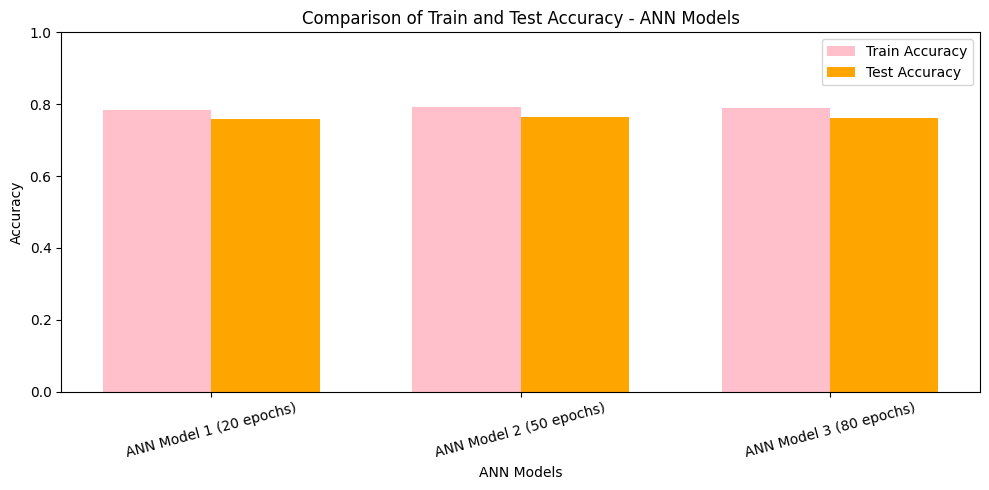

In [ ]:
# === Step 1: Accuracy values for each ANN model ===
# Replace these with the actual values printed from your model evaluation
model_names = ["ANN Model 1 (20 epochs)", "ANN Model 2 (50 epochs)", "ANN Model 3 (80 epochs)"]
all_results = [results1, results2, results3]
train_accuracies = [r["train_acc"] for r in all_results]
test_accuracies  = [r["test_acc"]  for r in all_results]

# === Step 2: Print results in tabular format ===
print("\n📊 ANN Model Accuracy Comparison")
print("Model\t\t\t\tTrain Accuracy\tTest Accuracy")
for name, train_acc, test_acc in zip(model_names, train_accuracies, test_accuracies):
    print(f"{name:<30}{train_acc:.4f}\t\t{test_acc:.4f}")

# === Step 3: Visualize with a Bar Chart ===
x = range(len(model_names))
bar_width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x, train_accuracies, width=bar_width, label='Train Accuracy', color='pink')
plt.bar([i + bar_width for i in x], test_accuracies, width=bar_width, label='Test Accuracy', color='orange')

plt.xticks([i + bar_width / 2 for i in x], model_names, rotation=15)
plt.ylim(0, 1)
plt.xlabel("ANN Models")
plt.ylabel("Accuracy")
plt.title("Comparison of Train and Test Accuracy - ANN Models")
plt.legend()
plt.tight_layout()
plt.show()


## **Interface**

In [34]:
import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML
import joblib
from tensorflow.keras.models import load_model
from scipy.stats import mode

# ========== Load Pre-trained Models ==========
knn_model = joblib.load('knn_model.pkl')
log_model = joblib.load('logistic_regression_model.pkl')
ann_model = load_model('ann_model.h5')
scaler = joblib.load('scaler.pkl')

# ========== Ensemble Prediction ==========
def ensemble_predict(X_scaled):
    preds = [
        knn_model.predict(X_scaled)[0],
        log_model.predict(X_scaled)[0],
        np.argmax(ann_model.predict(X_scaled), axis=1)[0]
    ]
    return int(mode(preds).mode[0])

# ========== Color Scheme ==========
COLORS = {
    'background': '#f0f9ff',
    'input_bg': '#ffffff',
    'button_bg': '#4CAF50',
    'highlight': '#2196F3',
    'text': '#2d3436',
    'success': '#8BC34A',
    'warning': '#FFC107',
    'danger': '#F44336',
    'border': '#BBDEFB'
}

# ========== Input Validation ==========
def validate_range(value, min_val, max_val, field_name):
    if value < min_val or value > max_val:
        raise ValueError(f"{field_name} must be between {min_val} and {max_val}")

# ========== Create Styled Input Widgets ==========
def create_input_widgets():
    common_layout = widgets.Layout(
        width='90%',
        margin='8px 0',
        padding='12px',
        border=f'2px solid {COLORS["border"]}',
        border_radius='8px'
    )
    input_style = {'description_width': '140px', 'font_size': '14px'}

    temp = widgets.BoundedFloatText(
        description="🌡️ Temperature (°C):",
        min=-50, max=60, step=0.1,
        style=input_style, layout=common_layout
    )
    humidity = widgets.FloatSlider(
        description="💧 Humidity:",
        min=0, max=1, step=0.01,
        readout_format='.0%', 
        style=input_style, layout=common_layout
    )
    wind_speed = widgets.BoundedFloatText(
        description="🌬️ Wind Speed (km/h):",
        min=0, max=150, step=1,
        style=input_style, layout=common_layout
    )
    wind_bearing = widgets.BoundedFloatText(
        description="🧭 Wind Bearing (°):",
        min=0, max=359.9, step=1,
        style=input_style, layout=common_layout
    )
    visibility = widgets.BoundedFloatText(
        description="👀 Visibility (km):",
        min=0, max=100, step=0.1,
        style=input_style, layout=common_layout
    )
    pressure = widgets.BoundedFloatText(
        description="⏲️ Pressure (mb):",
        min=800, max=1100, step=1,
        style=input_style, layout=common_layout
    )
    return temp, humidity, wind_speed, wind_bearing, visibility, pressure

temp, humidity, wind_speed, wind_bearing, visibility, pressure = create_input_widgets()

# ========== Prediction Button ==========
predict_btn = widgets.Button(
    description="✨ Get Weather Prediction",
    icon='magic',
    layout=widgets.Layout(
        height='60px',
        width='60%',
        padding='15px 20px',
        margin='20px auto',
        border=f'2px solid {COLORS["button_bg"]}',
        border_radius='25px'
    ),
    style=widgets.ButtonStyle(
        button_color=COLORS['button_bg'],
        font_weight='bold',
        font_size='14px'
    )
)

# ========== Real-time Input Validation ==========
result_display = widgets.Output()

def handle_input_change(change):
    with result_display:
        clear_output()
    try:
        validate_range(temp.value, temp.min, temp.max, "Temperature")
        validate_range(humidity.value, humidity.min, humidity.max, "Humidity")
        validate_range(wind_speed.value, wind_speed.min, wind_speed.max, "Wind Speed")
        validate_range(wind_bearing.value, wind_bearing.min, wind_bearing.max, "Wind Bearing")
        validate_range(visibility.value, visibility.min, visibility.max, "Visibility")
        validate_range(pressure.value, pressure.min, pressure.max, "Pressure")
    except ValueError as e:
        display(widgets.HTML(f"<div style='color: {COLORS['danger']}; margin: 10px'>⚠️ {str(e)}</div>"))

for widget in [temp, humidity, wind_speed, wind_bearing, visibility, pressure]:
    widget.observe(handle_input_change, names='value')

# ========== Help Text ==========
help_text = widgets.HTML(f"""
<div style='background: {COLORS['highlight']}15; padding: 20px; border-radius: 8px;
     margin: 20px 0; border-left: 4px solid {COLORS['highlight']}'>
    <strong style='color: {COLORS['text']}'>💡 Example Inputs:</strong><br>
    <div style='columns: 2; margin-top: 10px;'>
        <div>☀️ <strong>Clear Day</strong><br>25°C, 40%, 10km/h<br>180°, 15km, 1015mb</div>
        <div>🌧️ <strong>Rainy Day</strong><br>12°C, 95%, 25km/h<br>180°, 3km, 900mb</div>
        <div>⛅ <strong>Cloudy Day</strong><br>18°C, 65%, 15km/h<br>90°, 10km, 1005mb</div>
    </div>
</div>
""")

# ... (keep all previous imports and color scheme definitions)

# ========== Ensemble Prediction FIXED ==========
def ensemble_predict(X_scaled):
    # Get predictions from all models
    knn_pred = knn_model.predict(X_scaled)[0]
    log_pred = log_model.predict(X_scaled)[0]
    ann_pred = np.argmax(ann_model.predict(X_scaled), axis=1)[0]
    
    # Calculate mode safely
    from scipy.stats import mode
    mode_result = mode([knn_pred, log_pred, ann_pred])
    
    # Handle numpy array output from scipy.stats.mode
    if isinstance(mode_result.mode, np.ndarray):
        return int(mode_result.mode[0])
    else:
        return int(mode_result.mode)

# ========== Prediction Function FIXED ==========
def get_weather_prediction(b):
    with result_display:
        clear_output()
        try:
            # CORRECTED FEATURE NAMES WITH UNITS
            feature_columns = [
                'Temperature (C)',
                'Humidity',
                'Wind Speed (km/h)',
                'Wind Bearing (degrees)',
                'Visibility (km)',
                'Pressure (millibars)'
            ]
            
            input_data = pd.DataFrame([[
                temp.value,
                humidity.value,
                wind_speed.value,
                wind_bearing.value,
                visibility.value,
                pressure.value
            ]], columns=feature_columns)

            if input_data.isnull().any().any():
                raise ValueError("Please fill all fields")

            scaled_input = scaler.transform(input_data)
            final_pred = ensemble_predict(scaled_input)

            class_names = ['Clear', 'Cloudy', 'Precipitation']
            colors = [COLORS['success'], COLORS['warning'], COLORS['danger']]
            icons = ['☀️', '⛅', '🌧️']

            # Model predictions with error handling
            model_outputs = []
            for name, model in [('KNN', knn_model), 
                              ('Logistic Regression', log_model), 
                              ('ANN', ann_model)]:
                try:
                    if name == 'ANN':
                        ann_probs = model.predict(scaled_input)[0]
                        pred = np.argmax(ann_probs)
                        confidence = ann_probs[pred] * 100
                    else:
                        pred = model.predict(scaled_input)[0]
                        if hasattr(model, 'predict_proba'):
                            proba = model.predict_proba(scaled_input)[0]
                            confidence = proba[pred] * 100
                        else:
                            confidence = '-'
                    
                    confidence_display = f"{confidence:.1f}%" if isinstance(confidence, (float, int)) else confidence
                    
                    model_outputs.append(f"""
                        <div style='background: {colors[pred]}20; padding: 15px; border-radius: 8px;
                             margin: 10px 0; border: 2px solid {colors[pred]};
                             display: grid; grid-template-columns: 60px 1fr; align-items: center'>
                            <div style='font-size: 32px'>{icons[pred]}</div>
                            <div>
                                <strong>{name}</strong><br>
                                Prediction: {class_names[pred]}<br>
                                Confidence: {confidence_display}
                            </div>
                        </div>
                    """)
                except Exception as model_error:
                    model_outputs.append(f"""
                        <div style='background: {COLORS['danger']}20; padding: 15px; border-radius: 8px;
                             margin: 10px 0; border: 2px solid {COLORS['danger']}'>
                            ⚠️ {name} Error: {str(model_error)}
                        </div>
                    """)

            display(widgets.HTML(f"""
                <div style='background: {colors[final_pred]}20; padding: 25px; border-radius: 12px;
                     margin: 20px 0; border: 2px solid {colors[final_pred]}'>
                    <div style='text-align: center; margin-bottom: 20px'>
                        <div style='font-size: 48px'>{icons[final_pred]}</div>
                        <h2 style='color: {colors[final_pred]}; margin: 10px 0'>
                            {class_names[final_pred]}
                        </h2>
                        <div style='color: {COLORS['text']}'>
                            Ensemble Prediction (Majority Vote)
                        </div>
                    </div>
                    {"".join(model_outputs)}
                </div>
            """))

        except Exception as e:
            display(widgets.HTML(f"""
                <div style='background: {COLORS['danger']}20; color: {COLORS['danger']}; padding: 15px;
                     border-radius: 8px; margin: 10px; border: 2px solid {COLORS['danger']}'>
                    ⚠️ {str(e)}
                </div>
            """))

# ... (keep the rest of the UI layout and styling code)
# ========== Final UI Layout ==========
input_column = widgets.VBox([
    widgets.HTML("<h1 style='text-align: center; margin: 20px 0'>⛅ Smart Weather Predictor 🌦️</h1>"),
    temp, humidity, wind_speed, wind_bearing, visibility, pressure,
    predict_btn, help_text
], layout=widgets.Layout(
    width='40%',
    padding='30px',
    background_color=COLORS['background'],
    box_shadow='0 4px 20px rgba(0,0,0,0.08)',
    border_radius='16px',
    margin='0 20px 0 0'
))

output_column = widgets.VBox([
    widgets.HTML("<h2 style='margin: 0 0 20px 0'>🌦️ Prediction Analysis</h2>"),
    result_display
], layout=widgets.Layout(
    width='55%',
    padding='30px',
    background_color=COLORS['background'],
    box_shadow='0 4px 20px rgba(0,0,0,0.08)',
    border_radius='16px'
))

ui_layout = widgets.HBox([input_column, output_column],
    layout=widgets.Layout(
        width='95%',
        margin='20px auto',
        justify_content='space-between',
        align_items='flex-start'
    )
)

# ========== Custom CSS Styling ==========
display(HTML(f"""
<style>
    .widget-label {{ 
        color: {COLORS['text']} !important; 
        font-size: 14px !important; 
        font-weight: 600 !important; 
    }}
    .widget-text input, .widget-slider .ui-slider {{
        background: {COLORS['input_bg']} !important;
        border: 2px solid {COLORS['border']} !important;
        border-radius: 8px !important;
        padding: 10px !important;
        font-size: 14px !important;
    }}
    .widget-button:hover {{
        transform: translateY(-2px) !important;
        box-shadow: 0 5px 15px {COLORS['button_bg']}40 !important;
    }}
    .invalid-input input {{
        border-color: {COLORS['danger']} !important;
        background-color: {COLORS['danger']}15 !important;
    }}
</style>
"""))

# ========== Hook Button ==========
predict_btn.on_click(get_weather_prediction)
display(ui_layout)